Hệ số chặn (Intercept): 6532.710111699639
Hệ số góc (Slope): 32.99920901365975
MSE: 61916604.48599778
R^2 score: 0.06760188453580318


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


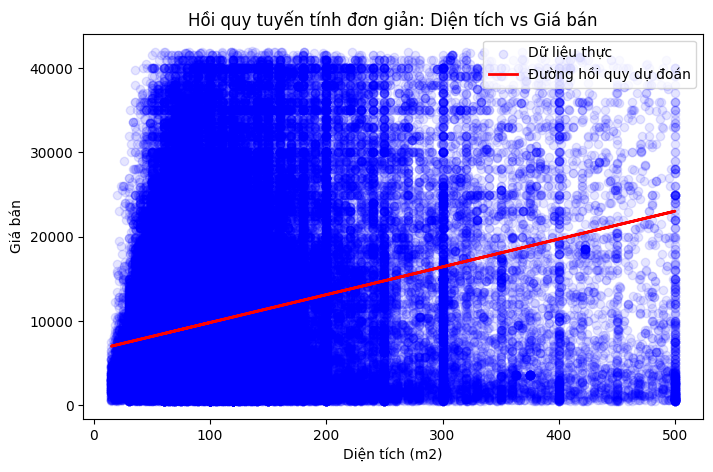

,Data (%),MAE,RMSE,R2
0,10.0,5808.648795,7868.831785,0.067573
1,20.0,5804.808172,7868.733656,0.067596
2,40.0,5806.271502,7868.761549,0.067590
3,60.0,5805.979571,7868.767586,0.067588
4,80.0,5805.009080,7868.735698,0.067596
5,100.0,5805.257976,7868.710472,0.067602


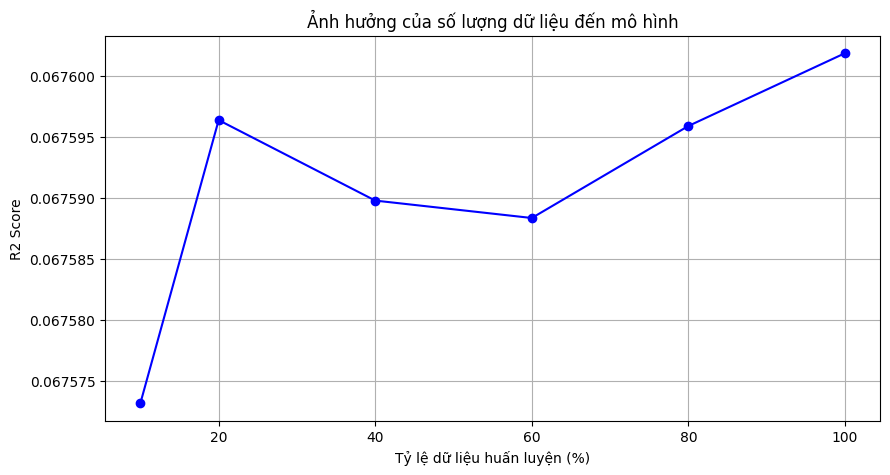

,Noise (%),MAE,RMSE,R2
0,0.0,5805.257976,7868.710472,0.067602
1,5.0,5805.130730,7868.711988,0.067602
2,10.0,5805.003503,7868.713546,0.067601
3,20.0,5804.749113,7868.716788,0.067600
4,30.0,5804.494918,7868.720195,0.067600


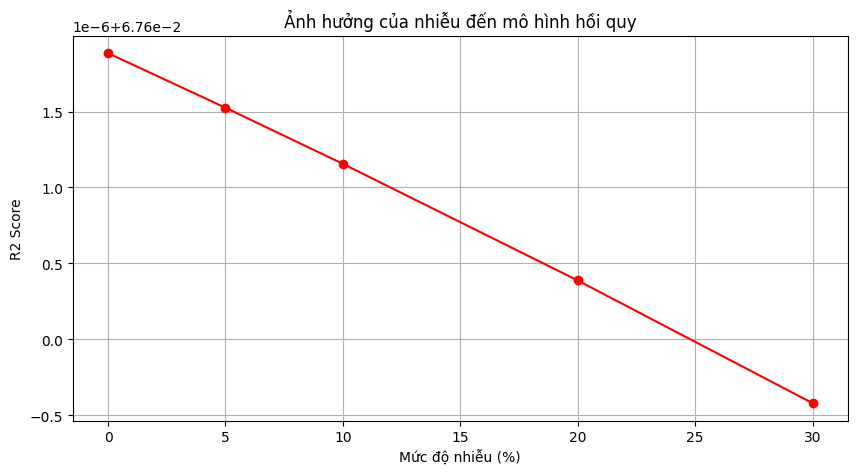

Hệ số chặn (Intercept): -116.17
Hệ số của area: 50.97
Hệ số của bedroom_count: 334.52
Hệ số của bathroom_count: 1180.33
MSE (đa biến): 28780314.75
R^2 (đa biến): 0.3277


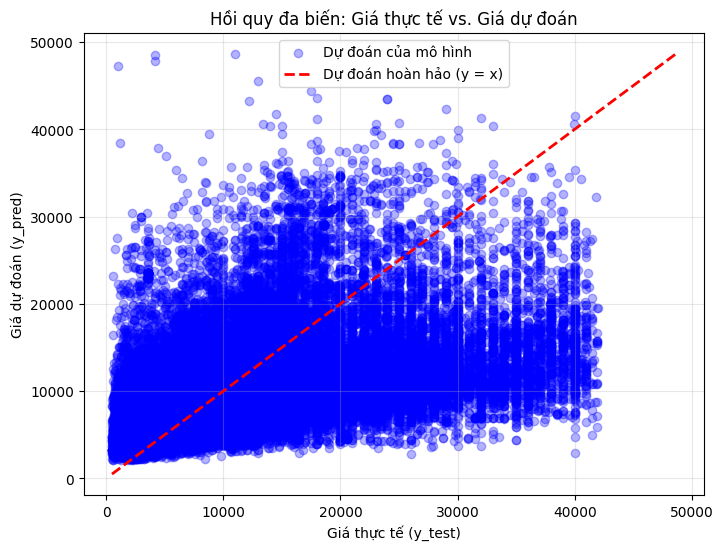

In [ ]:
#--------------BÀI 1-------------------
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from huggingface_hub import list_repo_files
from datasets import load_dataset
import pandas as pd

REPO = "tinixai/vietnam-real-estates"
files = sorted(f for f in list_repo_files(REPO, repo_type="dataset") if f.endswith(".parquet"))

cot = ["property_type_name", "province_name", "district_name", "price", "area",
       "bedroom_count", "bathroom_count", "published_at"]

df_goc = pd.concat(
    [pd.read_parquet(f"hf://datasets/{REPO}/{f}", columns=cot) for f in files[:5]],
    ignore_index=True)

df = df_goc.dropna(subset=["price", "area"]).copy()
df["price"] = pd.to_numeric(df["price"], errors="coerce")
df["area"] = pd.to_numeric(df["area"], errors="coerce")
df = df.dropna(subset=["price", "area"])
df = df[(df["area"] >= 15) & (df["area"] <= 500)]
df = df[(df["price"] > 0) & (df["price"] < df["price"].quantile(0.95))] # Bỏ 5% giá cao bất thường
df["price"] = df["price"] / 1_000_000
df = df[(df["price"] >= 500) & (df["price"] <= 50000)]
#print(f"Số lượng mẫu sau khi làm sạch: {len(df)}")

x = df[["area"]]
y = df["price"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(x_train, y_train)

y_pred = model.predict(x_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Hệ số chặn (Intercept): {model.intercept_:}")
print(f"Hệ số góc (Slope): {model.coef_[0]:}")
print(f"MSE: {mse:}")
print(f"R^2 score: {r2:}")

plt.figure(figsize=(8, 5))
plt.scatter(x_test, y_test, color="blue", alpha=0.1, label="Dữ liệu thực")
plt.plot(x_test, y_pred, color="red", linewidth=2, label="Đường hồi quy dự đoán")
plt.title("Hồi quy tuyến tính đơn giản: Diện tích vs Giá bán")
plt.xlabel("Diện tích (m2)")
plt.ylabel("Giá bán")
plt.legend()
plt.show()

percentages = [0.1, 0.2, 0.4, 0.6, 0.8, 1.0]

results = []

for p in percentages:

    n = max(2, int(len(x_train) * p))

    x_sample = x_train.iloc[:n]
    y_sample = y_train.iloc[:n]

    model = LinearRegression()
    model.fit(x_sample, y_sample)

    y_pred = model.predict(x_test)

    results.append({
        'Data (%)': p * 100,
        'MAE': mean_absolute_error(y_test, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
        'R2': r2_score(y_test, y_pred)
    })

result_df = pd.DataFrame(results)
display(result_df)
plt.figure(figsize=(10, 5))

plt.plot(result_df['Data (%)'], result_df['R2'],
         marker='o', color='blue')

plt.xlabel('Tỷ lệ dữ liệu huấn luyện (%)')
plt.ylabel('R2 Score')
plt.title('Ảnh hưởng của số lượng dữ liệu đến mô hình')

plt.grid()
plt.show()

noise_levels = [0, 0.05, 0.1, 0.2, 0.3]

noise_results = []

for noise in noise_levels:

    np.random.seed(42)

    noise_data = np.random.normal(
        loc=0,
        scale=noise,
        size=len(y_train)
    )

    y_noisy = y_train * (1 + noise_data)

    model = LinearRegression()
    model.fit(x_train, y_noisy)

    y_pred = model.predict(x_test)

    noise_results.append({
        'Noise (%)': noise * 100,
        'MAE': mean_absolute_error(y_test, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
        'R2': r2_score(y_test, y_pred)
    })

noise_df = pd.DataFrame(noise_results)

display(noise_df)
plt.figure(figsize=(10, 5))

plt.plot(noise_df['Noise (%)'], noise_df['R2'],
         marker='o', color='red')

plt.xlabel('Mức độ nhiễu (%)')
plt.ylabel('R2 Score')
plt.title('Ảnh hưởng của nhiễu đến mô hình hồi quy')

plt.grid()
plt.show()

features = ["area", "bedroom_count", "bathroom_count"]
df_multi = df.dropna(subset=features).copy()
df_multi = df_multi[(df_multi["bedroom_count"] <= 20) & (df_multi["bathroom_count"] <= 20)]

X_multi = df_multi[features]
y_multi = df_multi["price"]

X_tr, X_te, y_tr, y_te = train_test_split(X_multi, y_multi, test_size=0.2, random_state=42)

model_multi = LinearRegression()
model_multi.fit(X_tr, y_tr)

y_pr = model_multi.predict(X_te)
print(f"Hệ số chặn (Intercept): {model_multi.intercept_:.2f}")
for col, coef in zip(features, model_multi.coef_):
    print(f"Hệ số của {col}: {coef:.2f}")

print(f"MSE (đa biến): {mean_squared_error(y_te, y_pr):.2f}")
print(f"R^2 (đa biến): {r2_score(y_te, y_pr):.4f}")

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_te, y_pr, color="blue", alpha=0.3, label="Dự đoán của mô hình")

min_val = min(y_te.min(), y_pr.min())
max_val = max(y_te.max(), y_pr.max())
plt.plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", linewidth=2, label="Dự đoán hoàn hảo (y = x)")

plt.title("Hồi quy đa biến: Giá thực tế vs. Giá dự đoán")
plt.xlabel("Giá thực tế (y_test)")
plt.ylabel("Giá dự đoán (y_pred)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Số dòng ban đầu: 100000

Hệ số chặn (Intercept): -3.4031
Hệ số góc (Slope): 0.1168
Độ chính xác (Accuracy): 0.7295
ROC-AUC: 0.6979

Ma trận nhầm lẫn (Confusion Matrix):
[[13114  4388]
 [  803   885]]

Báo cáo phân loại (Classification Report):
              precision    recall  f1-score   support

           0       0.94      0.75      0.83     17502
           1       0.17      0.52      0.25      1688

    accuracy                           0.73     19190
   macro avg       0.56      0.64      0.54     19190
weighted avg       0.87      0.73      0.78     19190



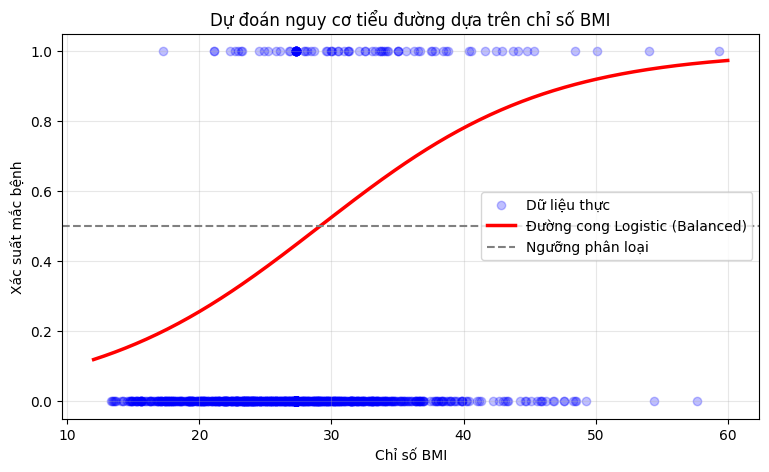

In [ ]:
#--------------BÀI 2-------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score

df = pd.read_csv('diabetes_prediction_dataset.csv')
print(f"Số dòng ban đầu: {len(df)}")

df_clean = df.drop_duplicates()
df_clean = df_clean[(df_clean['bmi'] >= 12) & (df_clean['bmi'] <= 60)]

X = df_clean[['bmi']]
y = df_clean['diabetes']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = LogisticRegression(class_weight='balanced', random_state=42)
model.fit(X_train, y_train)

y_prob = model.predict_proba(X_test)[:, 1]
y_pred = model.predict(X_test)

print(f"\nHệ số chặn (Intercept): {model.intercept_[0]:.4f}")
print(f"Hệ số góc (Slope): {model.coef_[0][0]:.4f}")
print(f"Độ chính xác (Accuracy): {accuracy_score(y_test, y_pred):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob):.4f}")
print("\nMa trận nhầm lẫn (Confusion Matrix):")
print(confusion_matrix(y_test, y_pred))
print("\nBáo cáo phân loại (Classification Report):")
print(classification_report(y_test, y_pred))

sample_idx = np.random.choice(len(X_test), size=1000, replace=False)
X_sample = X_test.iloc[sample_idx]
y_sample = y_test.iloc[sample_idx]

bmi_range = pd.DataFrame(np.linspace(12, 60, 300), columns=['bmi'])
prob_curve = model.predict_proba(bmi_range)[:, 1]

plt.figure(figsize=(9, 5))
plt.scatter(X_sample, y_sample, color="blue", alpha=0.25, label="Dữ liệu thực")
plt.plot(bmi_range, prob_curve, color="red", linewidth=2.5, label="Đường cong Logistic (Balanced)")
plt.axhline(0.5, color="gray", linestyle="--", label="Ngưỡng phân loại")
plt.title("Dự đoán nguy cơ tiểu đường dựa trên chỉ số BMI")
plt.xlabel("Chỉ số BMI")
plt.ylabel("Xác suất mắc bệnh")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Kích thước dữ liệu: (7310, 13)
Số giá trị thiếu: 0
Số dòng trùng lặp: 0

Hệ số chặn (Intercept): 14.6819
Hệ số hồi quy (Coefficients):
  - Temperature_Min (°C): 0.7982
  - Humidity (%): 0.0010
  - Rainfall (mm): -0.0007
  - Wind_Speed (km/h): 0.0007
  - AQI: -0.0001
  - Pressure (hPa): 0.0002
  - Cloud_Cover (%): 0.0016

Mean Squared Error (MSE): 6.6999
Root Mean Squared Error (RMSE): 2.5884 °C
R^2 score: 0.7987


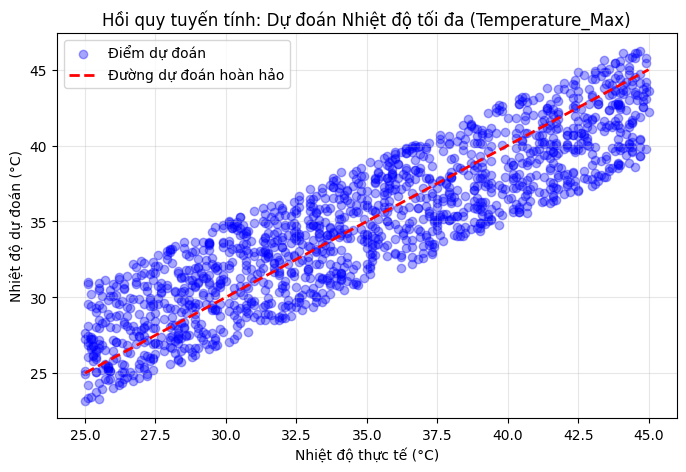

In [ ]:
#--------------BÀI 3-------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv('Indian_Climate_Dataset_2024_2025.csv')
print(f"Kích thước dữ liệu: {df.shape}")
print(f"Số giá trị thiếu: {df.isnull().sum().sum()}")
print(f"Số dòng trùng lặp: {df.duplicated().sum()}")

features = [
    'Temperature_Min (°C)', 'Humidity (%)', 'Rainfall (mm)',
    'Wind_Speed (km/h)', 'AQI', 'Pressure (hPa)', 'Cloud_Cover (%)'
]
X = df[features]
y = df['Temperature_Max (°C)']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"\nHệ số chặn (Intercept): {model.intercept_:.4f}")
print("Hệ số hồi quy (Coefficients):")
for col, coef in zip(features, model.coef_):
    print(f"  - {col}: {coef:.4f}")

print(f"\nMean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f} °C")
print(f"R^2 score: {r2:.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.35, color='blue', label='Điểm dự đoán')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
         color='red', linestyle='--', linewidth=2, label='Đường dự đoán hoàn hảo')
plt.title("Hồi quy tuyến tính: Dự đoán Nhiệt độ tối đa (Temperature_Max)")
plt.xlabel("Nhiệt độ thực tế (°C)")
plt.ylabel("Nhiệt độ dự đoán (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()